<a href="https://colab.research.google.com/github/FSFontoura/desafio_bootcamp_dio_deteccao_fraudes_transacoes_bancarias/blob/main/desafio_bootcamp_dio_deteccao_fraudes_transacoes_bancarias.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [39]:
import pandas as pd
url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

df = pd.read_csv(url)
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [40]:
print("Linhas e colunas:", df.shape)
print("\nFraude (1) vs Normal (0):")
print(df["Class"].value_counts())
print("\nProporção (%):")
print((df["Class"].value_counts(normalize=True) * 100).round(3))

Linhas e colunas: (284807, 31)

Fraude (1) vs Normal (0):
Class
0    284315
1       492
Name: count, dtype: int64

Proporção (%):
Class
0    99.827
1     0.173
Name: proportion, dtype: float64


In [41]:
df.groupby('Class')['Amount'].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


In [42]:
import numpy as np

df['Amount_log'] = np.log1p(df['Amount'])

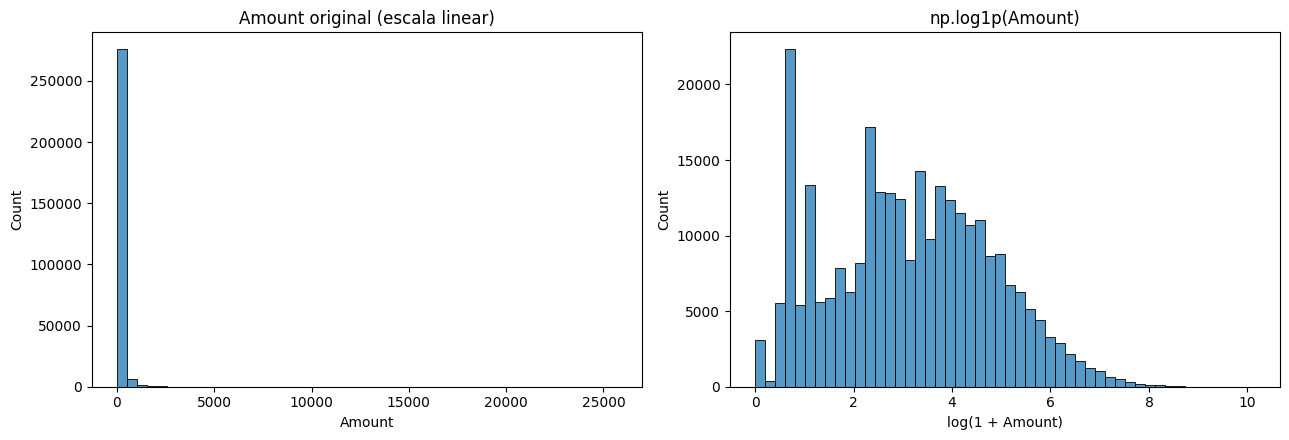

In [43]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

amount_log = np.log1p(df["Amount"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(df["Amount"], bins=50, ax=axes[0])
axes[0].set_title("Amount original (escala linear)")
axes[0].set_xlabel("Amount")

sns.histplot(amount_log, bins=50, ax=axes[1])
axes[1].set_title("np.log1p(Amount)")
axes[1].set_xlabel("log(1 + Amount)")

plt.tight_layout()
plt.show()

In [44]:
hora_relativa = (df["Time"] // 3600) % 24
df.groupby(hora_relativa)["Amount"].agg(["count", "mean", "median"])

,count,mean,median
Time,,,
0.0,7695,60.325960,12.140
1.0,4220,62.636363,18.980
2.0,3328,70.258618,17.165
3.0,3492,52.076793,15.950
4.0,2209,77.039036,15.950
5.0,2990,50.675645,11.850
6.0,4101,65.060278,11.850
7.0,7243,67.818459,15.000
8.0,10276,88.771243,25.955


In [45]:
hora_relativa = ((df["Time"] // 3600) % 24).rename("hora_relativa")

fraudes_por_hora = df.groupby(hora_relativa)["Class"].agg(
    total_transacoes="count",
    total_fraudes="sum",
    taxa_fraude="mean",
)

fraudes_por_hora

,total_transacoes,total_fraudes,taxa_fraude
hora_relativa,,,
0.0,7695,6,0.000780
1.0,4220,10,0.002370
2.0,3328,57,0.017127
3.0,3492,17,0.004868
4.0,2209,23,0.010412
5.0,2990,11,0.003679
6.0,4101,9,0.002195
7.0,7243,23,0.003175
8.0,10276,9,0.000876


In [46]:
hora_relativa = ((df["Time"] // 3600) % 24).rename("hora_relativa")

resumo_hora_classe = df.groupby([hora_relativa, "Class"])["Amount"].agg(
    qtd="count",
    media_amount="mean",
    mediana_amount="median",
)

resumo_hora_classe.head(60)

qtd  media_amount  mediana_amount
hora_relativa Class                                     
0.0           0       7689     60.136323          12.140
              1          6    303.345000         230.240
1.0           0       4210     62.481266          18.965
              1         10    127.932000          45.725
2.0           0       3271     70.101712          17.450
              1         57     79.262807           1.000
3.0           0       3475     52.264245          15.950
              1         17     13.759412           1.000
4.0           0       2186     77.141368          15.950
              1         23     67.313043           2.280
5.0           0       2979     50.387214          11.850
              1         11    128.788182           1.000
6.0           0       4092     64.957204          11.850
              1          9    111.924444           3.120
7.0           0       7220     67.652537          15.000
              1         23    119.903478          99.990
8.0           0      10267     88.807081          25.950
              1          9     47.887778          30.300
9.0           0      15822    102.867805          31.000
              1         16     78.463125          16.710
10.0          0      16590    109.584374          33.000
              1          8    293.701250          26.155
11.0          0      16803    109.567984          32.550
              1         53    123.976038          39.450
12.0          0      15403    105.941393          29.990
              1         17    200.384706           2.000
13.0          0      15348     98.925988          27.520
              1         17    129.087059           7.580
14.0          0      16547    103.462369          26.540
              1         23    158.309565          99.990
15.0          0      16435    102.024674          27.500
              1         26     85.926538           3.245
16.0          0      16431    103.347603          26.770
              1         22    204.793182          13.490
17.0          0      16137     98.291284          23.050
              1         29    116.327586           1.590
18.0          0      17006     77.029648          18.000
              1         33    192.276970           6.740
19.0          0      15630     77.945983          19.310
              1         19    111.296316           3.900
20.0          0      16738     74.534753          18.405
              1         18     83.911667          37.585
21.0          0      17687     71.667647          17.990
              1         16     64.343750          26.145
22.0          0      15432     69.823340          15.000
              1          9    160.222222          19.950
23.0          0      10917     68.757904          14.400
              1         21    149.672381          42.530

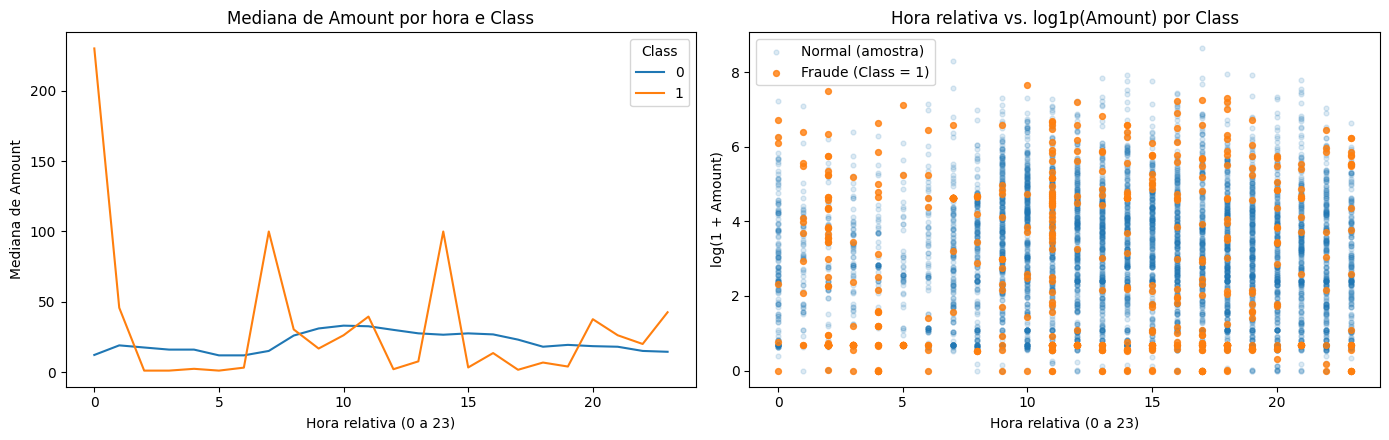

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

df_plot = df.copy()
df_plot["hora_relativa"] = (df_plot["Time"] // 3600) % 24
df_plot["amount_log"] = np.log1p(df_plot["Amount"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# 1) Valor mediano de Amount por hora, separado por Class
sns.lineplot(
    data=df_plot,
    x="hora_relativa",
    y="Amount",
    hue="Class",
    estimator="median",
    errorbar=None,
    ax=axes[0],
)
axes[0].set_title("Mediana de Amount por hora e Class")
axes[0].set_xlabel("Hora relativa (0 a 23)")
axes[0].set_ylabel("Mediana de Amount")

# 2) Dispersão de hora vs. log1p(Amount) destacando fraudes
normais = df_plot[df_plot["Class"] == 0].sample(n=5000, random_state=42)
fraudes = df_plot[df_plot["Class"] == 1]

axes[1].scatter(
    normais["hora_relativa"],
    normais["amount_log"],
    alpha=0.15,
    s=12,
    label="Normal (amostra)",
)
axes[1].scatter(
    fraudes["hora_relativa"],
    fraudes["amount_log"],
    alpha=0.8,
    s=18,
    label="Fraude (Class = 1)",
)
axes[1].set_title("Hora relativa vs. log1p(Amount) por Class")
axes[1].set_xlabel("Hora relativa (0 a 23)")
axes[1].set_ylabel("log(1 + Amount)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [48]:
from sklearn.model_selection import train_test_split

# Exemplo ajustando Amount_log e hora_relativa a partir do df
df_prep = df.copy()
df_prep["Amount_log"] = np.log1p(df_prep["Amount"])
df_prep["hora_relativa"] = (df_prep["Time"] // 3600) % 24

X = df_prep.drop(columns=["Class", "Amount"])
y = df_prep["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=42,
)

print("X:", X.shape, "| y:", y.shape)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X: (284807, 31) | y: (284807,)
X_train: (199364, 31) | X_test: (85443, 31)


In [49]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled: ", X_test_scaled.shape)

X_train_scaled: (199364, 31)
X_test_scaled:  (85443, 31)


In [50]:
from sklearn.model_selection import train_test_split

X = df.drop(['Class'], axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.3, random_state=42)

In [51]:
from sklearn.linear_model import LogisticRegression

modelo = LogisticRegression(
    class_weight="balanced", max_iter=1000, random_state=42
)
modelo.fit(X_train_scaled, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [52]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

y_prob = modelo.predict_proba(X_test_scaled)[:, 1]

limiares = [0.5, 0.3]
resultados = []

for limiar in limiares:
    y_pred = (y_prob >= limiar).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    precisao = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
    recall = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
    f1 = f1_score(y_test, y_pred, pos_label=1, zero_division=0)

    resultados.append(
        {
            "limiar": limiar,
            "precisao_fraude": precisao,
            "recall_fraude": recall,
            "f1_fraude": f1,
            "VP (TP)": tp,
            "FN (FN)": fn,
            "FP (FP)": fp,
            "VN (TN)": tn,
        }
    )

    print(f"=== Limiar >= {limiar} ===")
    print("Matriz de confusão [[TN, FP], [FN, TP]]:")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, digits=4))

df_avaliacao = pd.DataFrame(resultados)
display(df_avaliacao)

=== Limiar >= 0.5 ===
Matriz de confusão [[TN, FP], [FN, TP]]:
[[83402  1893]
 [   20   128]]
              precision    recall  f1-score   support

           0     0.9998    0.9778    0.9887     85295
           1     0.0633    0.8649    0.1180       148

    accuracy                         0.9776     85443
   macro avg     0.5315    0.9213    0.5533     85443
weighted avg     0.9981    0.9776    0.9872     85443

=== Limiar >= 0.3 ===
Matriz de confusão [[TN, FP], [FN, TP]]:
[[81083  4212]
 [   16   132]]
              precision    recall  f1-score   support

           0     0.9998    0.9506    0.9746     85295
           1     0.0304    0.8919    0.0588       148

    accuracy                         0.9505     85443
   macro avg     0.5151    0.9213    0.5167     85443
weighted avg     0.9981    0.9505    0.9730     85443



,limiar,precisao_fraude,recall_fraude,f1_fraude,VP (TP),FN (FN),FP (FP),VN (TN)
0,0.5,0.063335,0.864865,0.118027,128,20,1893,83402
1,0.3,0.030387,0.891892,0.058771,132,16,4212,81083


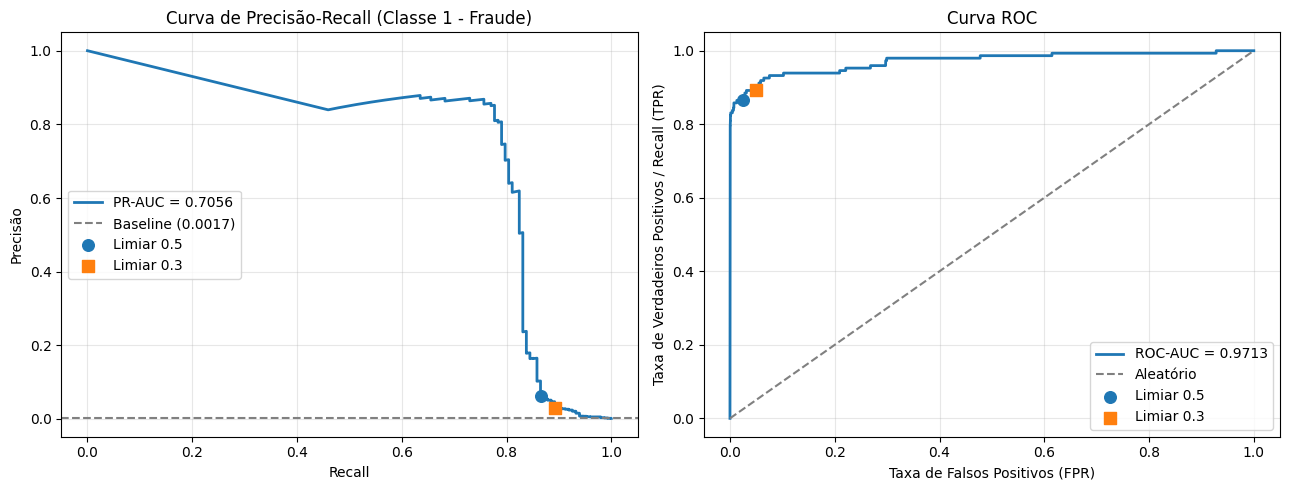

In [53]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)

# Probabilidade da classe positiva (fraude = 1) no conjunto de teste
y_prob = modelo.predict_proba(X_test_scaled)[:, 1]

# Cálculo das curvas e áreas sob a curva
precision, recall, pr_thresholds = precision_recall_curve(y_test, y_prob)
ap_score = average_precision_score(y_test, y_prob)

fpr, tpr, roc_thresholds = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- 1. Curva de Precisão-Recall ---
axes[0].plot(recall, precision, label=f"PR-AUC = {ap_score:.4f}", linewidth=2)
axes[0].axhline(
    y=y_test.mean(),
    color="gray",
    linestyle="--",
    label=f"Baseline ({y_test.mean():.4f})",
)

for limiar, marcador in [(0.5, "o"), (0.3, "s")]:
    idx = np.argmin(np.abs(pr_thresholds - limiar))
    axes[0].scatter(
        recall[idx],
        precision[idx],
        marker=marcador,
        s=70,
        zorder=5,
        label=f"Limiar {limiar}",
    )

axes[0].set_title("Curva de Precisão-Recall (Classe 1 - Fraude)")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precisão")
axes[0].legend(loc="best")
axes[0].grid(True, alpha=0.3)

# --- 2. Curva ROC ---
axes[1].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}", linewidth=2)
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Aleatório")

for limiar, marcador in [(0.5, "o"), (0.3, "s")]:
    idx = np.argmin(np.abs(roc_thresholds - limiar))
    axes[1].scatter(
        fpr[idx],
        tpr[idx],
        marker=marcador,
        s=70,
        zorder=5,
        label=f"Limiar {limiar}",
    )

axes[1].set_title("Curva ROC")
axes[1].set_xlabel("Taxa de Falsos Positivos (FPR)")
axes[1].set_ylabel("Taxa de Verdadeiros Positivos / Recall (TPR)")
axes[1].legend(loc="best")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [54]:
from imblearn.over_sampling import SMOTE
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

# 1. Balancear APENAS o conjunto de treino escalonado
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)

print("Antes do SMOTE:", pd.Series(y_train).value_counts().to_dict())
print("Depois do SMOTE:", pd.Series(y_train_bal).value_counts().to_dict())

# 2. Treinar o modelo nos dados balanceados
# Dica: com SMOTE, comece sem class_weight='balanced' para não duplicar o peso da classe 1
modelo_bal = LogisticRegression(max_iter=1000, random_state=42)
modelo_bal.fit(X_train_bal, y_train_bal)

# 3. Avaliar no X_test_scaled REAL com limiar >= 0.3
y_prob_bal = modelo_bal.predict_proba(X_test_scaled)[:, 1]
limiar = 0.3
y_pred_bal = (y_prob_bal >= limiar).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_bal).ravel()
print(f"\n=== Modelo com SMOTE | Limiar >= {limiar} ===")
print(
    f"Precisão: {precision_score(y_test, y_pred_bal, zero_division=0):.4f} | "
    f"Recall: {recall_score(y_test, y_pred_bal, zero_division=0):.4f} | "
    f"F1: {f1_score(y_test, y_pred_bal, zero_division=0):.4f}"
)
print(f"VP: {tp} | FN: {fn} | FP: {fp} | VN: {tn}")
print(classification_report(y_test, y_pred_bal, digits=4))

Antes do SMOTE: {0: 199020, 1: 344}
Depois do SMOTE: {0: 199020, 1: 199020}

=== Modelo com SMOTE | Limiar >= 0.3 ===
Precisão: 0.0322 | Recall: 0.8986 | F1: 0.0621
VP: 133 | FN: 15 | FP: 4002 | VN: 81293
              precision    recall  f1-score   support

           0     0.9998    0.9531    0.9759     85295
           1     0.0322    0.8986    0.0621       148

    accuracy                         0.9530     85443
   macro avg     0.5160    0.9259    0.5190     85443
weighted avg     0.9981    0.9530    0.9743     85443



In [55]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from xgboost import XGBClassifier

# 1. Instanciar modelos (sem duplicar balanceamento se já usou SMOTE/undersampling)
rf_bal = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    n_jobs=-1,
    random_state=42,
)

xgb_bal = XGBClassifier(
    n_estimators=150,
    max_depth=6,
    learning_rate=0.1,
    eval_metric="logloss",
    n_jobs=-1,
    random_state=42,
)

modelos_bal = {
    "Random Forest (bal)": rf_bal,
    "XGBoost (bal)": xgb_bal,
}

limiar = 0.3
resumo = []

for nome, clf in modelos_bal.items():
    clf.fit(X_train_bal, y_train_bal)
    y_prob = clf.predict_proba(X_test_scaled)[:, 1]
    y_pred = (y_prob >= limiar).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    precisao = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
    recall = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
    f1 = f1_score(y_test, y_pred, pos_label=1, zero_division=0)

    resumo.append(
        {
            "modelo": nome,
            "limiar": limiar,
            "precisao_fraude": precisao,
            "recall_fraude": recall,
            "f1_fraude": f1,
            "VP": tp,
            "FN": fn,
            "FP": fp,
            "VN": tn,
        }
    )

    print(f"\n=== {nome} | Limiar >= {limiar} ===")
    print(f"VP: {tp} | FN: {fn} | FP: {fp} | VN: {tn}")
    print(classification_report(y_test, y_pred, digits=4))

df_modelos_bal = pd.DataFrame(resumo)
display(df_modelos_bal)


=== Random Forest (bal) | Limiar >= 0.3 ===
VP: 125 | FN: 23 | FP: 341 | VN: 84954
              precision    recall  f1-score   support

           0     0.9997    0.9960    0.9979     85295
           1     0.2682    0.8446    0.4072       148

    accuracy                         0.9957     85443
   macro avg     0.6340    0.9203    0.7025     85443
weighted avg     0.9985    0.9957    0.9968     85443


=== XGBoost (bal) | Limiar >= 0.3 ===
VP: 123 | FN: 25 | FP: 158 | VN: 85137
              precision    recall  f1-score   support

           0     0.9997    0.9981    0.9989     85295
           1     0.4377    0.8311    0.5734       148

    accuracy                         0.9979     85443
   macro avg     0.7187    0.9146    0.7862     85443
weighted avg     0.9987    0.9979    0.9982     85443



,modelo,limiar,precisao_fraude,recall_fraude,f1_fraude,VP,FN,FP,VN
0,Random Forest (bal),0.3,0.268240,0.844595,0.407166,125,23,341,84954
1,XGBoost (bal),0.3,0.437722,0.831081,0.573427,123,25,158,85137


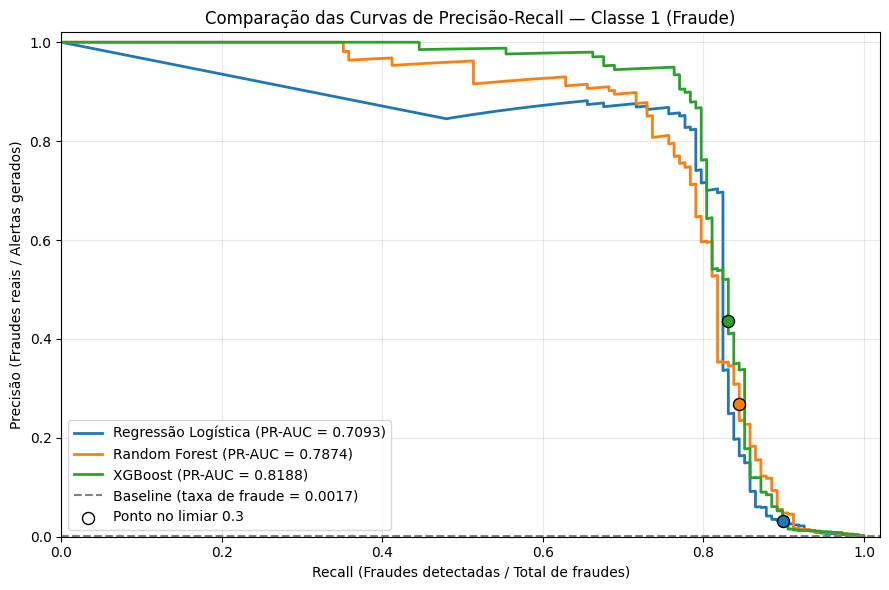

In [56]:
from sklearn.metrics import average_precision_score, precision_recall_curve

# Ajuste os nomes das variáveis conforme você salvou cada estimador treinado:
# ex.: modelo / modelo_bal, rf_bal, xgb_bal
estimadores = {
    "Regressão Logística": modelo_bal,  # ou 'modelo' se for o estimador anterior
    "Random Forest": rf_bal,
    "XGBoost": xgb_bal,
}

limiar_destaque = 0.3

plt.figure(figsize=(9, 6))

for nome, clf in estimadores.items():
    y_prob = clf.predict_proba(X_test_scaled)[:, 1]
    precision, recall, thresholds = precision_recall_curve(y_test, y_prob)
    ap = average_precision_score(y_test, y_prob)

    linha = plt.plot(
        recall, precision, linewidth=2, label=f"{nome} (PR-AUC = {ap:.4f})"
    )
    cor_linha = linha[0].get_color()

    # Marca o ponto mais próximo do limiar 0.3
    if len(thresholds) > 0:
        idx = np.argmin(np.abs(thresholds - limiar_destaque))
        plt.scatter(
            recall[idx],
            precision[idx],
            color=cor_linha,
            edgecolor="black",
            s=75,
            zorder=5,
        )

# Linha base correspondente à proporção real de fraudes no teste
baseline = y_test.mean()
plt.axhline(
    y=baseline,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label=f"Baseline (taxa de fraude = {baseline:.4f})",
)

# Entrada de legenda apenas para o marcador do limiar 0.3
plt.scatter(
    [],
    [],
    color="white",
    edgecolor="black",
    s=75,
    label=f"Ponto no limiar {limiar_destaque}",
)

plt.title("Comparação das Curvas de Precisão-Recall — Classe 1 (Fraude)")
plt.xlabel("Recall (Fraudes detectadas / Total de fraudes)")
plt.ylabel("Precisão (Fraudes reais / Alertas gerados)")
plt.xlim([0.0, 1.02])
plt.ylim([0.0, 1.02])
plt.legend(loc="best")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

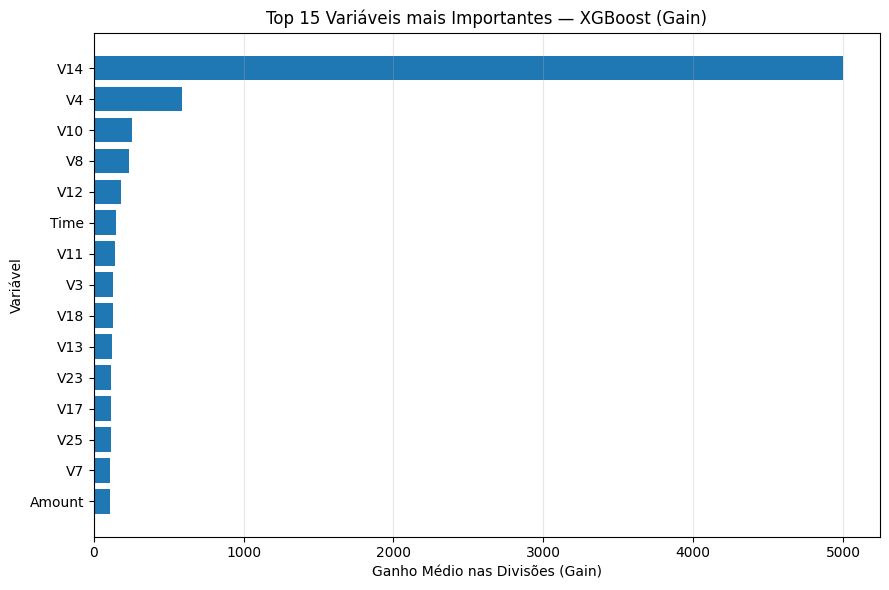

,feature,ganho_medio
0,V14,4997.365234
1,V4,586.081543
2,V10,255.484207
3,V8,236.152237
4,V12,183.093826
5,Time,150.063797
6,V11,144.580063
7,V3,127.780769
8,V18,125.461929
9,V13,121.676964


In [57]:
import matplotlib.pyplot as plt

# Extrai importância por ganho médio (quanto cada feature melhora as divisões das árvores)
# Outras opções: "weight" (frequência de uso) ou "cover" (número de amostras afetadas)
scores_dict = xgb_bal.get_booster().get_score(importance_type="gain")

# Mapeia chaves "f0", "f1", ... para os nomes reais das colunas em X_train
nomes_colunas = list(X_train.columns)
mapeamento = {f"f{i}": col for i, col in enumerate(nomes_colunas)}

df_importancia = pd.DataFrame(
    [
        {
            "feature": mapeamento.get(feat_key, feat_key),
            "ganho_medio": valor,
        }
        for feat_key, valor in scores_dict.items()
    ]
).sort_values("ganho_medio", ascending=False)

top_n = 15
top_df = df_importancia.head(top_n).iloc[::-1]

plt.figure(figsize=(9, 6))
plt.barh(top_df["feature"], top_df["ganho_medio"])
plt.title(f"Top {top_n} Variáveis mais Importantes — XGBoost (Gain)")
plt.xlabel("Ganho Médio nas Divisões (Gain)")
plt.ylabel("Variável")
plt.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

display(df_importancia.head(top_n).reset_index(drop=True))

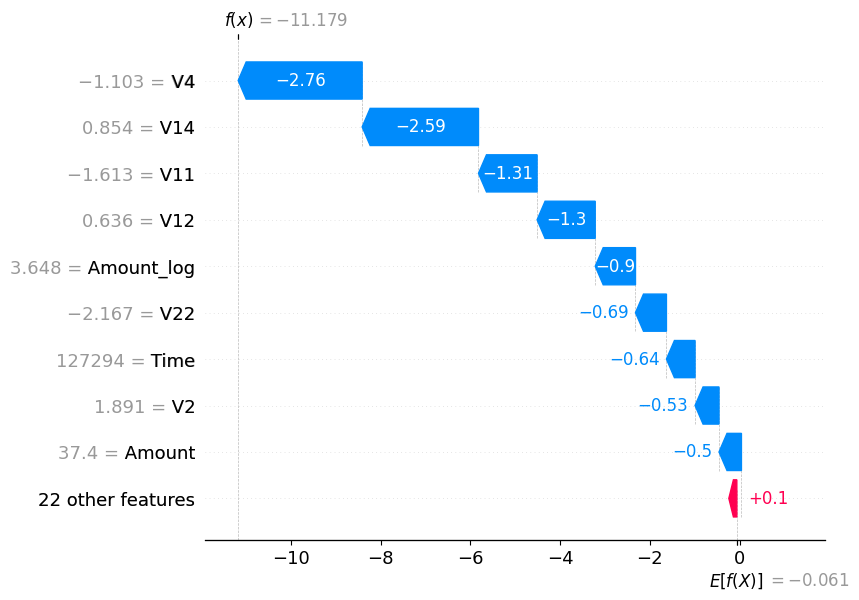

In [58]:
import shap

# Inicializando o explicador do SHAP para o modelo XGBoost balanceado
explainer = shap.Explainer(xgb_bal)
shap_values = explainer(X_test[:100])

# Exibindo o gráfico de waterfall para a primeira previsão do conjunto de teste
shap.plots.waterfall(shap_values[0])